In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
from scipy.integrate import odeint
from scipy.linalg import solve_continuous_lyapunov

In [3]:
def covariance_modes(covariances):
    C=np.asarray(covariances,float)
    n,p=C.shape[:2]
    vals=np.full((n,p),np.nan);vectors=np.full((n,p),np.nan)
    finite=np.isfinite(C).all(axis=(1,2))
    if finite.any():
        lam,V=np.linalg.eigh((C[finite]+C[finite].transpose(0,2,1))/2)
        vals[finite]=np.maximum(lam,0);vectors[finite]=V[:,:,-1]
    leading=vals[:,-1];norm=np.linalg.norm(vals,axis=1)
    q=np.divide(leading,norm,out=np.full(n,np.nan),where=norm>0)
    vectors[leading==0]=np.nan
    angle=np.full(n,np.nan)
    if n>1:
        cosine=np.abs(np.einsum("ti,ti->t",vectors[:-1],vectors[1:]))
        angle[1:]=np.arccos(np.clip(cosine,0,1))
    return {"lambda1":leading,"normalised_l2":q,"gap":leading-vals[:,-2],
            "vector":vectors,"angle":angle}

In [4]:
simulation_path = Path("Old_Cases/Cluster_Results")
old_figure_path = Path("Figures")
rev_figs = Path("Rev_Figures_Small")
old_figure_path.mkdir(parents=True, exist_ok=True)
rev_figs.mkdir(parents=True, exist_ok=True)

quantiles = (0.025, 0.5, 0.975)

# One total-infectious peak sets one common shift for all cities in each run.
# Alternatively set peak_reference to 1, 2, or 3 for that city's peak.
peak_reference = "total"
peak_plot_days = 20.0

qs_stab_tol = 1e-8
qs_res_tol = 1e-7
run_review_figs = True
save_new_figs = True
save_rev_tables = False

In [5]:
def symmetric_matrix(theta):
    theta = np.asarray(theta, dtype=float).ravel()
    n = int((np.sqrt(1 + 8 * theta.size) - 1) / 2)
    matrix = np.zeros((n, n))
    matrix[np.triu_indices(n)] = theta
    return matrix + matrix.T - np.diag(np.diag(matrix))


def extract_theta(matrix):
    matrix = np.asarray(matrix, dtype=float)
    return matrix[np.triu_indices(matrix.shape[0])].copy()


def covariance_summary(covariance):
    covariance = np.asarray(covariance, dtype=float)
    shape = covariance.shape[:-2]
    k = covariance.shape[-1]
    flat = covariance.reshape(-1, k, k)
    eigenvalues = np.full((len(flat), k), np.nan)
    vectors = np.full((len(flat), k), np.nan)
    finite = np.isfinite(flat).all(axis=(1, 2))
    if finite.any():
        vals, vecs = np.linalg.eigh(0.5 * (flat[finite] + flat[finite].transpose(0, 2, 1)))
        vals = np.maximum(vals, 0.0)
        eigenvalues[finite] = vals
        vectors[finite] = vecs[:, :, -1]
    norm = np.linalg.norm(eigenvalues, axis=1)
    ratio = np.full(len(flat), np.nan)
    np.divide(eigenvalues[:, -1], norm, out=ratio, where=norm > 0)
    vectors[norm == 0] = np.nan
    return {
        "eigenvalues": eigenvalues.reshape(*shape, k),
        "lambda1": eigenvalues[:, -1].reshape(shape),
        "normalised": ratio.reshape(shape),
        "eigenvector": vectors.reshape(*shape, k),
    }


def covariance_to_correlation(covariance):
    covariance = np.asarray(covariance, dtype=float)
    diagonal = np.diagonal(covariance, axis1=-2, axis2=-1)
    standard_deviation = np.sqrt(np.maximum(diagonal, 0.0))
    denominator = standard_deviation[..., :, None] * standard_deviation[..., None, :]
    correlation = np.full_like(covariance, np.nan)
    np.divide(covariance, denominator, out=correlation, where=denominator > 0)
    return correlation


def ensemble_covariance(runs, population):
    residual = (runs - runs.mean(axis=0, keepdims=True)) / np.sqrt(population)
    return np.einsum("rct,rdt->tcd", residual, residual) / (len(runs) - 1)

def interpolate_series(times, values, new_times):
    """Interpolate on the final time axis, with no extrapolation."""
    times, new_times = np.asarray(times), np.asarray(new_times)
    tol = 1e-9 * max(1.0, np.ptp(times))
    target = np.clip(new_times, times[0], times[-1])
    flat = np.asarray(values).reshape(-1, len(times))
    out = np.array([np.interp(target, times, row) for row in flat])
    return out.reshape(*np.shape(values)[:-1], len(target))


def crossing_times(times, values, level=0.0):
    times, values = np.asarray(times), np.asarray(values) - level
    roots = list(times[np.isclose(values, 0.0, atol=1e-12, rtol=0.0)])
    for i in np.flatnonzero(values[:-1] * values[1:] < 0):
        roots.append(times[i] - values[i] * (times[i + 1] - times[i]) / (values[i + 1] - values[i]))
    return np.unique(np.round(roots, 12))


def _run_array(array, n_times):
    """Normalise the pre-review saved-array layouts to (run, 3, time)."""
    array = np.asarray(array)
    if array.ndim == 3 and array.shape[1:] == (3, n_times):
        pass
    elif array.ndim == 3 and array.shape[1:] == (n_times, 3):
        array = array.transpose(0, 2, 1)
    elif array.ndim == 2 and array.shape == (n_times, 3):
        array = array.T[None, :, :]
    elif array.ndim == 2 and array.shape[1] == n_times and array.shape[0] % 3 == 0:
        array = array.reshape(-1, 3, n_times)
    elif array.ndim == 1 and array.size % (3 * n_times) == 0:
        array = array.reshape(-1, 3, n_times)
    array = np.asarray(array, dtype=float)
    return array


def load_simulation_runs(folder_name, n_times):
    folder = simulation_path / folder_name
    def files_for(prefix):
        return {p.name[1:]: p for p in sorted(folder.glob(f"{prefix}*.npy"))}
    infectious_files, susceptible_files = files_for("I"), files_for("S")
    infectious_chunks, susceptible_chunks, paths = [], [], []
    for suffix, i_path in infectious_files.items():
        s_path = susceptible_files[suffix]
        i_chunk = _run_array(np.load(i_path, mmap_mode="r", allow_pickle=False), n_times)
        s_chunk = _run_array(np.load(s_path, mmap_mode="r", allow_pickle=False), n_times)
        infectious_chunks.append(i_chunk)
        susceptible_chunks.append(s_chunk)
        paths.append({"I": str(i_path), "S": str(s_path), "runs": len(i_chunk)})
    infectious = np.concatenate(infectious_chunks, axis=0)
    susceptible = np.concatenate(susceptible_chunks, axis=0)
    return infectious, susceptible, paths

In [6]:
def jacobian_and_diffusion(S_counts, I_counts, beta, gamma, mu, population):
    s = np.asarray(S_counts, dtype=float) / population
    i = np.asarray(I_counts, dtype=float) / population
    beta = np.asarray(beta, dtype=float)
    force = beta @ i
    infection = s * force
    J_ss = np.diag(-mu - force)
    J_si = -s[:, None] * beta
    J_is = np.diag(force)
    J_ii = s[:, None] * beta - (gamma + mu) * np.eye(3)
    J = np.block([[J_ss, J_si], [J_is, J_ii]])

    B_ss = np.diag(mu * (1 - s) + infection)
    B_si = np.diag(-mu * i - infection)
    B_ii = np.diag((gamma + mu) * i + infection)
    B = np.block([[B_ss, B_si], [B_si.T, B_ii]])
    return J, B


def meta_int(X, t, betat, gamma, mu, Na):
    S, I, theta = X[:3], X[3:6], X[6:]
    beta = np.asarray(betat(t), dtype=float)
    force = (beta @ I) / Na
    dS = -force * S + (Na - S) * mu
    dI = force * S - (gamma + mu) * I
    J, B = jacobian_and_diffusion(S, I, beta, gamma, mu, Na)
    covariance = symmetric_matrix(theta)
    derivative = J @ covariance + covariance @ J.T + B
    return np.concatenate([dS, dI, extract_theta(derivative)])

$R_0=1/(\gamma+\mu)*\rho(\beta)$

In [7]:
# system parameters
gamma = 0.1
mu = 1/(80*365)
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
np.max(np.linalg.eigvals(beta_matrix))/(gamma+mu)

4.005684465099393

In [8]:
def analyze_epidemic_data(folder_name, betat, ts, gamma, mu, N_population, Si, Ii, etol):
    # etol is retained for compatibility; actual crossings are now interpolated.
    ts = np.asarray(ts, dtype=float)
    initial = np.r_[Si, Ii, np.zeros(21)]
    theory = odeint(meta_int, initial, ts, args=(betat, gamma, mu, N_population),
                    rtol=1e-8, atol=1e-10, mxstep=10000)
    full_covariance = np.array([symmetric_matrix(row[6:]) for row in theory])
    covariance = full_covariance[:, 3:, 3:]
    summary = covariance_summary(covariance)
    # Freeze each scenario's actual beta trajectory; later redefinitions of betat
    # cannot change a previously computed diagnostic.
    beta_matrices = np.array([betat(t) for t in ts], dtype=float)
    next_generation = theory[:, :3, None] * beta_matrices / (N_population * (gamma + mu))
    Reff = np.max(np.abs(np.linalg.eigvals(next_generation)), axis=-1)
    roots = crossing_times(ts, Reff, level=1.0)
    crossings = np.array([np.argmin(np.abs(ts - t)) for t in roots], dtype=int)
    infectious, susceptible, archives = load_simulation_runs(f"{folder_name}_small", len(ts))
    result = {
        "scenario": folder_name, "times": ts, "population": N_population,
        "gamma": gamma, "mu": mu, "beta_matrices": beta_matrices,
        "theory": theory, "full_covariance": full_covariance,
        "covariance": covariance, "eigvals": summary["lambda1"],
        "norm_eigvals": summary["normalised"], "eigvec": summary["eigenvector"],
        "Reff": Reff, "crossings": crossings, "crossing_times": roots,
        "infectious_runs": infectious, "susceptible_runs": susceptible,
        "simulation_archives": archives,
        "n_realisations": 0 if infectious is None else len(infectious),
    }
    if infectious is None:
        result.update({
            "ensemble_covariance": np.full_like(covariance, np.nan),
            "mean_per_time": np.full((3, len(ts)), np.nan),
            "I_lb": np.full((2, 3, len(ts)), np.nan),
            "sim_eigvals": np.full(len(ts), np.nan),
            "sim_norm_eigvals": np.full(len(ts), np.nan),
            "sim_eigvec": np.full((len(ts), 3), np.nan),
            "Reff_sims": np.full(len(ts), np.nan),
            "Reff_lb": np.full((2, len(ts)), np.nan),
        })
        return result

    covariance_sim = ensemble_covariance(infectious, N_population)
    summary_sim = covariance_summary(covariance_sim)
    R_runs = np.empty((len(infectious), len(ts)))
    for j, beta in enumerate(beta_matrices):
        matrices = susceptible[:, :, j, None] * beta / (N_population * (gamma + mu))
        R_runs[:, j] = np.max(np.abs(np.linalg.eigvals(matrices)), axis=-1)
    result.update({
        "ensemble_covariance": covariance_sim,
        "mean_per_time": infectious.mean(axis=0),
        "I_lb": np.quantile(infectious, [0.025, 0.975], axis=0),
        "sim_eigvals": summary_sim["lambda1"],
        "sim_norm_eigvals": summary_sim["normalised"],
        "sim_eigvec": summary_sim["eigenvector"],
        "Reff_sims": R_runs.mean(axis=0),
        "Reff_lb": np.quantile(R_runs, [0.025, 0.975], axis=0),
    })
    return result

In [9]:
def frozen_covariance_at(J, B, stability_tol=qs_stab_tol,
                         residual_tol=qs_res_tol):
    """Solve J C + C J.T + B = 0 only for a Hurwitz-stable frozen drift."""
    J, B = np.asarray(J, dtype=float), np.asarray(B, dtype=float)
    spectral_abscissa = float(np.max(np.linalg.eigvals(J).real))
    output = {"spectral_abscissa": spectral_abscissa,
              "covariance": np.full_like(B, np.nan),
              "relative_residual": np.nan, "minimum_eigenvalue": np.nan,
              "status": "unstable_or_neutral"}
    if spectral_abscissa >= -stability_tol:
        return output
    try:
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always", RuntimeWarning)
            # SciPy solves J C + C J.T = Q, hence Q = -B.
            covariance = solve_continuous_lyapunov(J, -B)
        covariance = 0.5 * (covariance + covariance.T)
        residual = np.linalg.norm(J @ covariance + covariance @ J.T + B, ord="fro")
        residual /= max(np.linalg.norm(B, ord="fro"), np.finfo(float).tiny)
        minimum = float(np.linalg.eigvalsh(covariance)[0])
        output.update(relative_residual=residual, minimum_eigenvalue=minimum)
        if caught:
            output["status"] = "solver_warning"
        elif not np.isfinite(covariance).all() or residual > residual_tol:
            output["status"] = "residual_failed"
        elif minimum < -1e-9 * max(np.linalg.norm(covariance, ord=2), np.finfo(float).tiny):
            output["status"] = "not_positive_semidefinite"
        else:
            output["status"] = "stable"
            output["covariance"] = covariance
    except (ValueError, np.linalg.LinAlgError) as exc:
        output["status"] = f"solver_failed: {type(exc).__name__}"
    return output


def quasistatic_diagnostics(result):
    n = len(result["times"])
    J_all, B_all = np.empty((n, 6, 6)), np.empty((n, 6, 6))
    covariance = np.full((n, 6, 6), np.nan)
    spectral = np.empty(n)
    infection_spectral = np.empty(n)
    numerical = np.empty(n)
    residuals = np.full(n, np.nan)
    minimums = np.full(n, np.nan)
    statuses = []
    for j, state in enumerate(result["theory"]):
        J, B = jacobian_and_diffusion(state[:3], state[3:6], result["beta_matrices"][j],
                                      result["gamma"], result["mu"], result["population"])
        J_all[j], B_all[j] = J, B
        solution = frozen_covariance_at(J, B)
        covariance[j] = solution["covariance"]
        spectral[j] = solution["spectral_abscissa"]
        infection_spectral[j] = np.max(np.linalg.eigvals(J[3:, 3:]).real)
        numerical[j] = np.linalg.eigvalsh(0.5 * (J + J.T))[-1]
        residuals[j] = solution["relative_residual"]
        minimums[j] = solution["minimum_eigenvalue"]
        statuses.append(solution["status"])
    infectious_covariance = covariance[:, 3:, 3:]
    summary = covariance_summary(infectious_covariance)
    valid = np.array(statuses) == "stable"
    ratio = np.full(n, np.nan)
    np.divide(result["eigvals"], summary["lambda1"], out=ratio,
              where=valid & (summary["lambda1"] > 0))
    denominator = np.linalg.norm(infectious_covariance, axis=(1, 2))
    frobenius_ratio = np.full(n, np.nan)
    relative_gap = np.full(n, np.nan)
    np.divide(np.linalg.norm(result["covariance"], axis=(1, 2)), denominator,
              out=frobenius_ratio, where=valid & (denominator > 0))
    np.divide(np.linalg.norm(result["covariance"] - infectious_covariance, axis=(1, 2)),
              denominator, out=relative_gap, where=valid & (denominator > 0))
    return {
        "J": J_all, "B": B_all, "full_covariance": covariance,
        "covariance": infectious_covariance, "summary": summary, "valid": valid,
        "status": np.array(statuses), "spectral_abscissa": spectral,
        "infection_block_spectral_abscissa": infection_spectral,
        "numerical_abscissa": numerical, "relative_lyapunov_residual": residuals,
        "minimum_full_covariance_eigenvalue": minimums,
        "lambda1_dynamic_over_frozen": ratio,
        "frobenius_dynamic_over_frozen": frobenius_ratio,
        "relative_matrix_gap": relative_gap,
        "infectious_noise_trace": np.trace(B_all[:, 3:, 3:], axis1=1, axis2=2),
        "jacobian_zero_crossings": crossing_times(result["times"], spectral),
    }

def plot_epidemic_results_single(results, ts, npi_time=None,save_path=None, legend=True, mini_loc="center right"):
    ts = np.asarray(ts)
    n = len(ts)
    fig, axs = plt.subplots(4, 1, figsize=(10, 18), sharex=True, constrained_layout=True)
    styles = ["solid", "dashed", "dotted"]
    colors = ["#E69F00", "#56B4E9", "#009E73"]
    for city in range(3):
        axs[0].plot(ts, results["theory"][:n, city + 3], linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[2].plot(ts, np.abs(results["eigvec"][:n, city]), linestyle=styles[city],
                    color=colors[city], label=f"Theory - City {city + 1}", linewidth=2)
        axs[0].plot(ts, results["mean_per_time"][city, :n], color=colors[city], alpha=0.7, label=f"Simulation - City {city + 1}", linewidth=1)
        axs[0].fill_between(ts, *results["I_lb"][:, city, :n], color=colors[city], alpha=0.15)
        axs[2].plot(ts, np.abs(results["sim_eigvec"][:n, city]), color=colors[city], alpha=0.7, linewidth=1)
    ax0 = axs[0].twinx()
    ax0.plot(ts, results["Reff"][:n], label=r"$R_t$ - Theory", linewidth=2, color="k")
    axs[1].plot(ts, results["eigvals"][:n], label=r"$\lambda_1$ - Theory", linewidth=2)
    # Invalid frozen solutions remain NaN, leaving gaps outside stable intervals.
    frozen = quasistatic_diagnostics(results)
    axs[1].plot(ts, frozen["summary"]["lambda1"][:n], color="C3",
                linestyle=":", linewidth=2, label=r"$\lambda_1$ - Quasi-static Theory")
    ax1 = axs[1].twinx()
    ax1.plot(ts, results["norm_eigvals"][:n], label=r"$\lambda_1/\|\lambda\|_2$ - Theory", linewidth=2, color = 'k')
    ax0.plot(ts, results["Reff_sims"][:n], "--", label=r"$R_t$ - Simulation", color = "r")
    ax0.fill_between(ts, *results["Reff_lb"][:, :n], alpha=0.15, color = "r")
    axs[1].plot(ts, results["sim_eigvals"][:n], "--", label=r"$\lambda_1$ - Simulation")
    ax1.plot(ts, results["sim_norm_eigvals"][:n], "--", label=r"$\lambda_1/\|\lambda\|_2$ - Simulation")
    comparisons=[("Eigenvalue gap - Theory",results["covariance"],"-")]
    comparisons.append(("Eigenvalue gap - Simulation",results["ensemble_covariance"],"--"))
    for label,C,style in comparisons:
        modes=covariance_modes(C[:n])
        axs[3].plot(ts,modes["gap"],style,label=label)
    comparisons=[("Angular Displacement - Theory",results["covariance"],"-")]
    ax3 = axs[3].twinx()
    ax3.plot(ts,covariance_modes(results["covariance"][:n])["angle"],"-",label="Angular Displacement - Theory",color="k")
    ax3.plot(ts,covariance_modes(results["ensemble_covariance"][:n])["angle"],"--",label="Angular Displacement - Simulation")
    roots = results["crossing_times"]
    for ax in axs:
        for root in roots[(roots >= ts[0]) & (roots <= ts[-1])]:
            ax.axvline(root, color="k", linestyle="--", alpha=0.6)
        if npi_time is not None and ts[0] <= npi_time <= ts[-1]:
            ax.axvline(npi_time, color="k", alpha=0.6)
        ax.grid(alpha=0.2)
        ax.tick_params(labelsize=12)
    labels = ["Number infectious", r"$R_t$", r"$\lambda_1$",
              r"$\lambda_1/\|\lambda\|_2$", "Absolute dominant eigenvector",
              r"Covariance gap $\lambda_1-\lambda_2$", "Eigenvector rotation (rad)"]
    axs_label = [axs[0], ax0, axs[1], ax1, axs[2], axs[3], ax3]
    for ax, label in zip(axs_label, labels):
        ax.set_ylabel(label, fontsize=13)
    axs[0].set_ylim(bottom=0)
    axs[1].set_ylim(bottom=0)
    axs[2].set_ylim(bottom=0)
    ax1.set_ylim(0, 1.05)
    axs[2].set_ylim(0, 1.05)
    axs[-1].set_xlabel("Time (days)")
    if legend:
        twin_pairs = [(axs[0], ax0), (axs[1], ax1), (axs[3], ax3)]
        for primary_ax, secondary_ax in twin_pairs:
            handles, labels_text = primary_ax.get_legend_handles_labels()
            if secondary_ax is not None:
                h2, l2 = secondary_ax.get_legend_handles_labels()
                handles += h2
                labels_text += l2
            if primary_ax == axs[1]:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="center right")
            else:
                primary_ax.legend(handles, labels_text, fontsize=10, loc="upper right")
    if save_path:
        path = Path(save_path)
        path.parent.mkdir(parents=True, exist_ok=True)
        fig.savefig(path, bbox_inches="tight")
    plt.show()
    plt.close(fig)


## Constant $\beta$

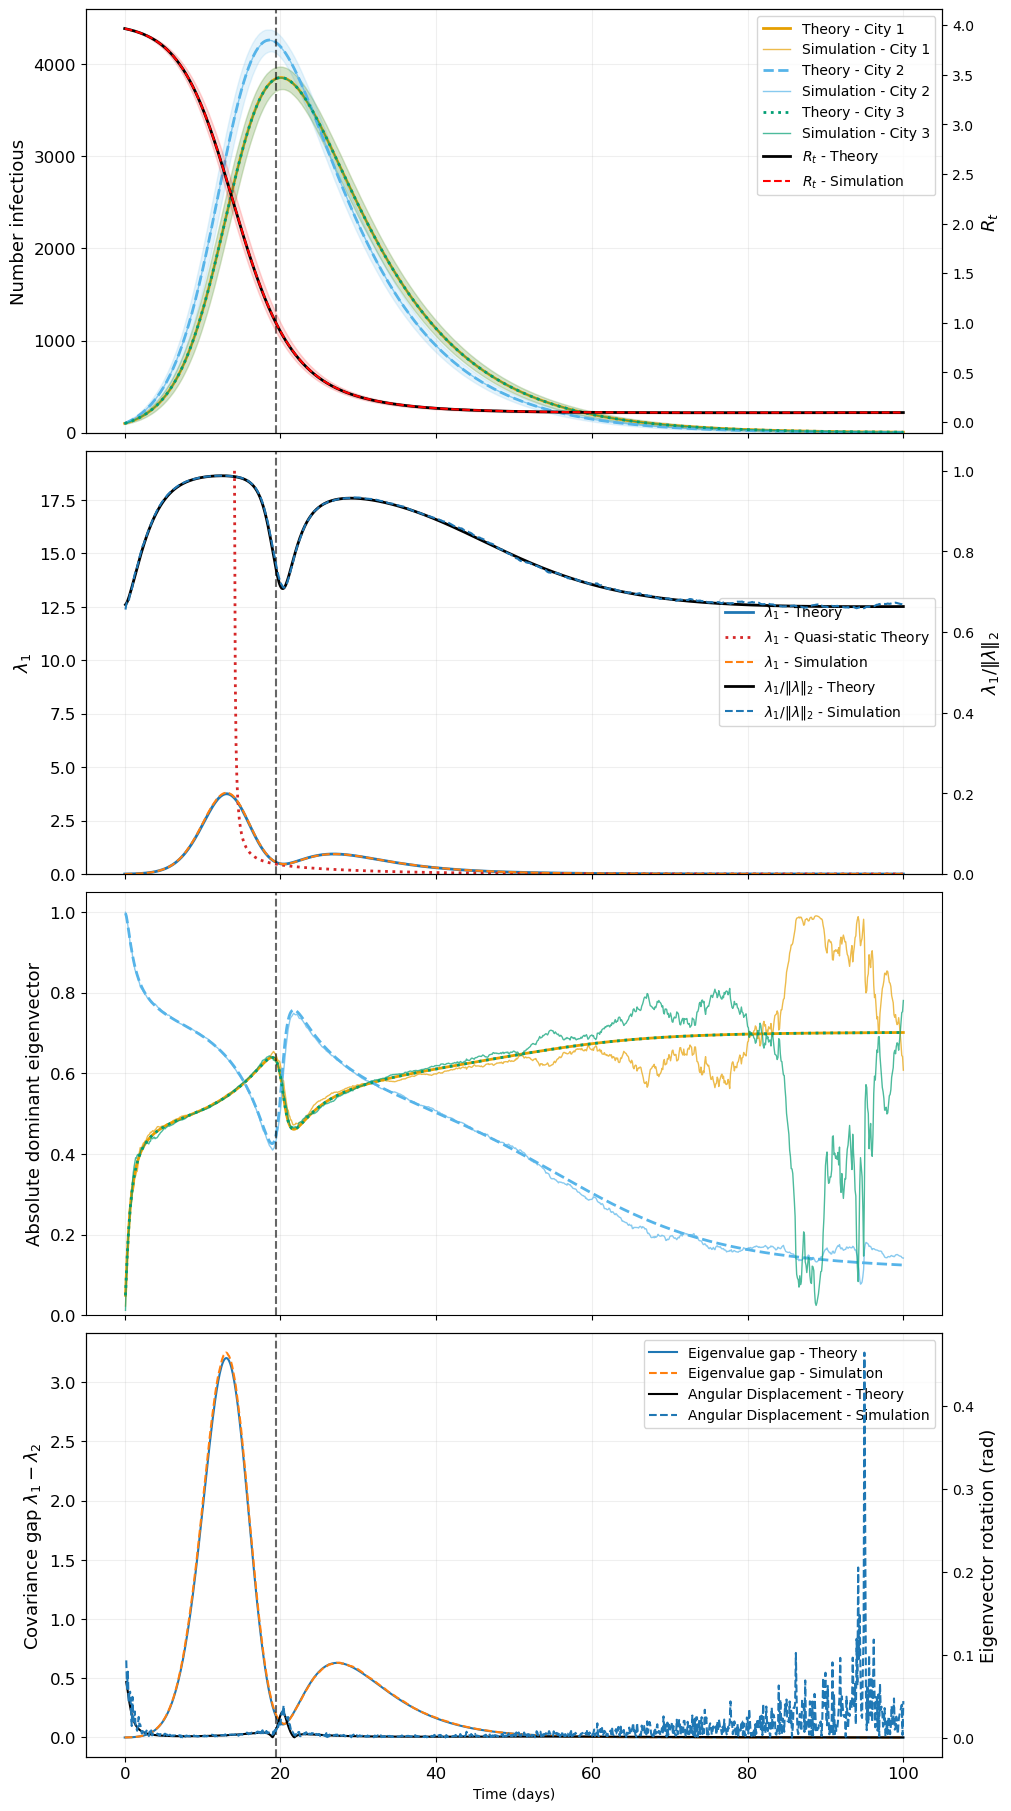

In [11]:
# parameters
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 10000

Ii = np.array([100,100,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
days = np.arange(0,101,1)
ts = np.arange(0,100.1,0.1)
results_constant = analyze_epidemic_data('constant', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_constant, ts, save_path='Rev_Figures_Small/cst_theory_small.pdf')

## Just b[1,1], full epidemic

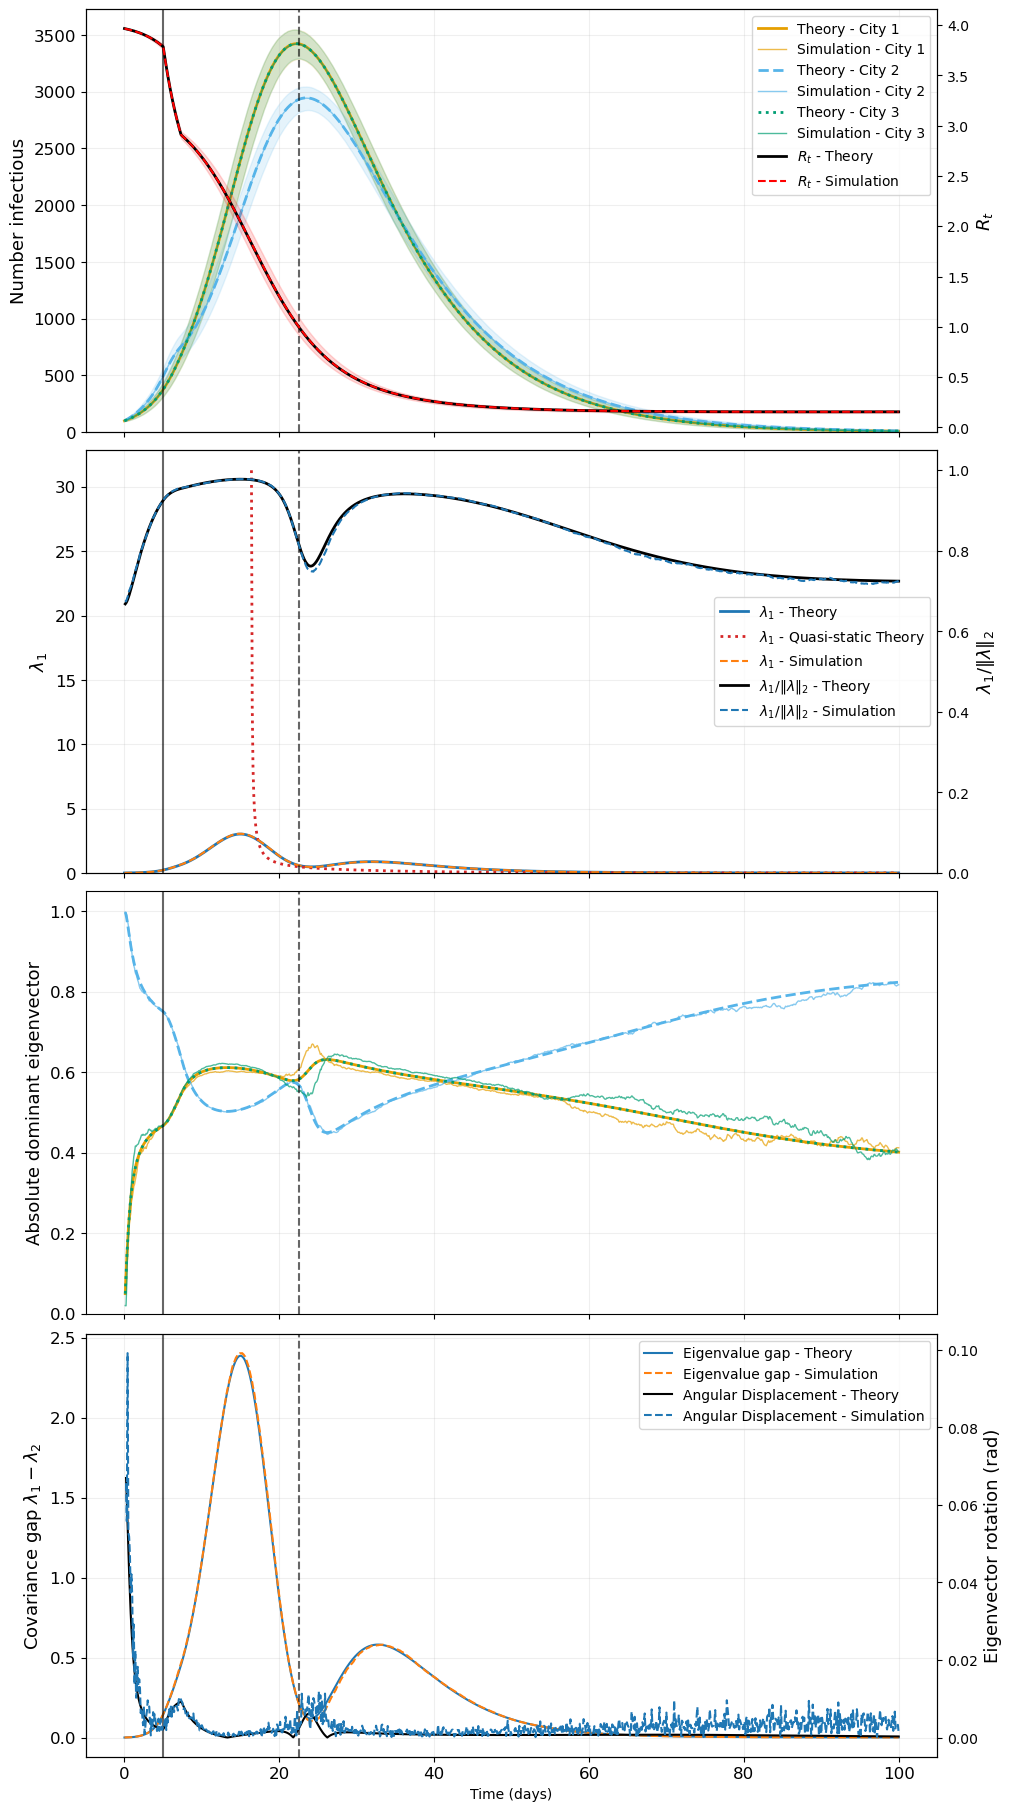

In [13]:
def betat(t):
    if t < 5:
        return beta_matrix
    else:
        temp = np.diag([0,1,0])
        return beta_matrix - 0.1*(t-5)*temp if (beta_matrix - 0.1*(t-5)*temp >= 0).all() else beta_matrix - np.diag([0,beta_matrix[1,1],0])
results_incity = analyze_epidemic_data('indec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_incity, ts, npi_time=5, save_path='Rev_Figures_Small/in_city_theory_small.pdf')

## Between cities

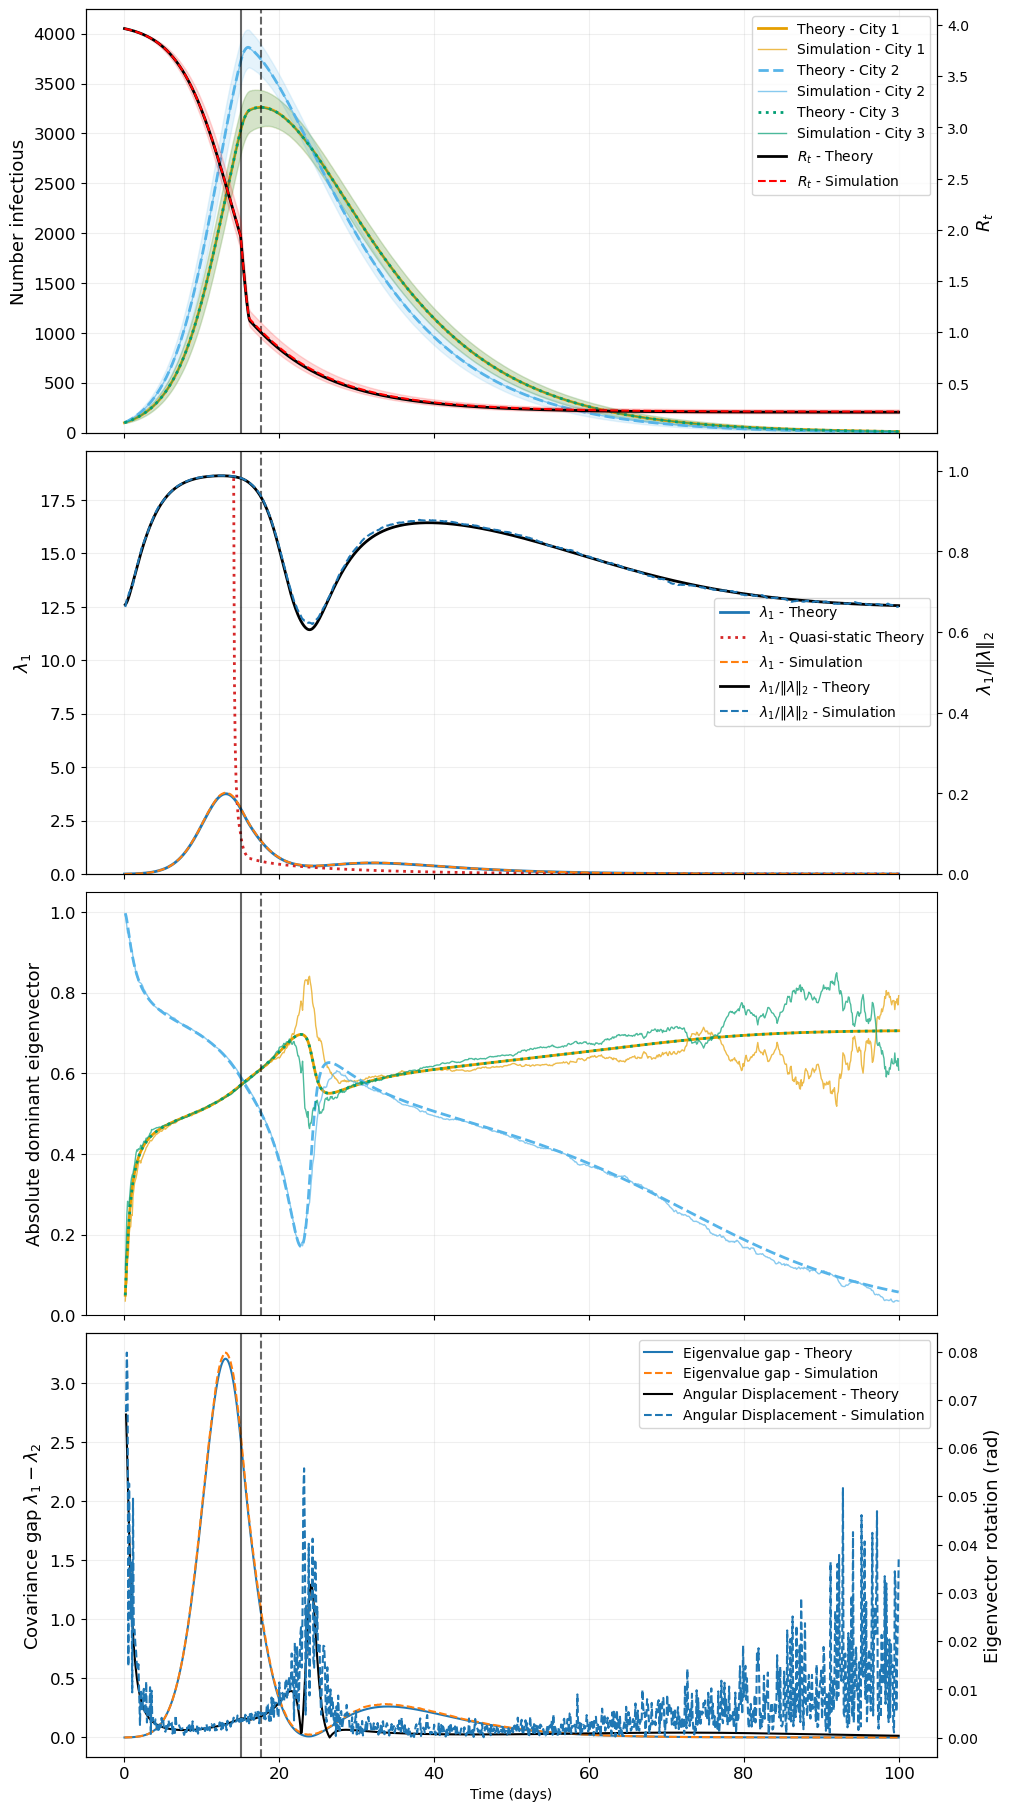

In [14]:
def betat(t):
    if t < 15:
        return beta_matrix
    else:
        temp = np.array([[0,1,0],[1,0,1],[0,1,0]])
        return beta_matrix - 0.1*(t-15)*temp if (beta_matrix - 0.1*(t-15)*temp >= 0).all() else beta_matrix - np.array([[0,b_b,0],[b_b,0,b_b],[0,b_b,0]])

results_between = analyze_epidemic_data('betdec', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_between, ts, npi_time=15, save_path='Rev_Figures_Small/bet_city_theory_small.pdf')

## New variant

0.8532611778611298
1.3303954541400647


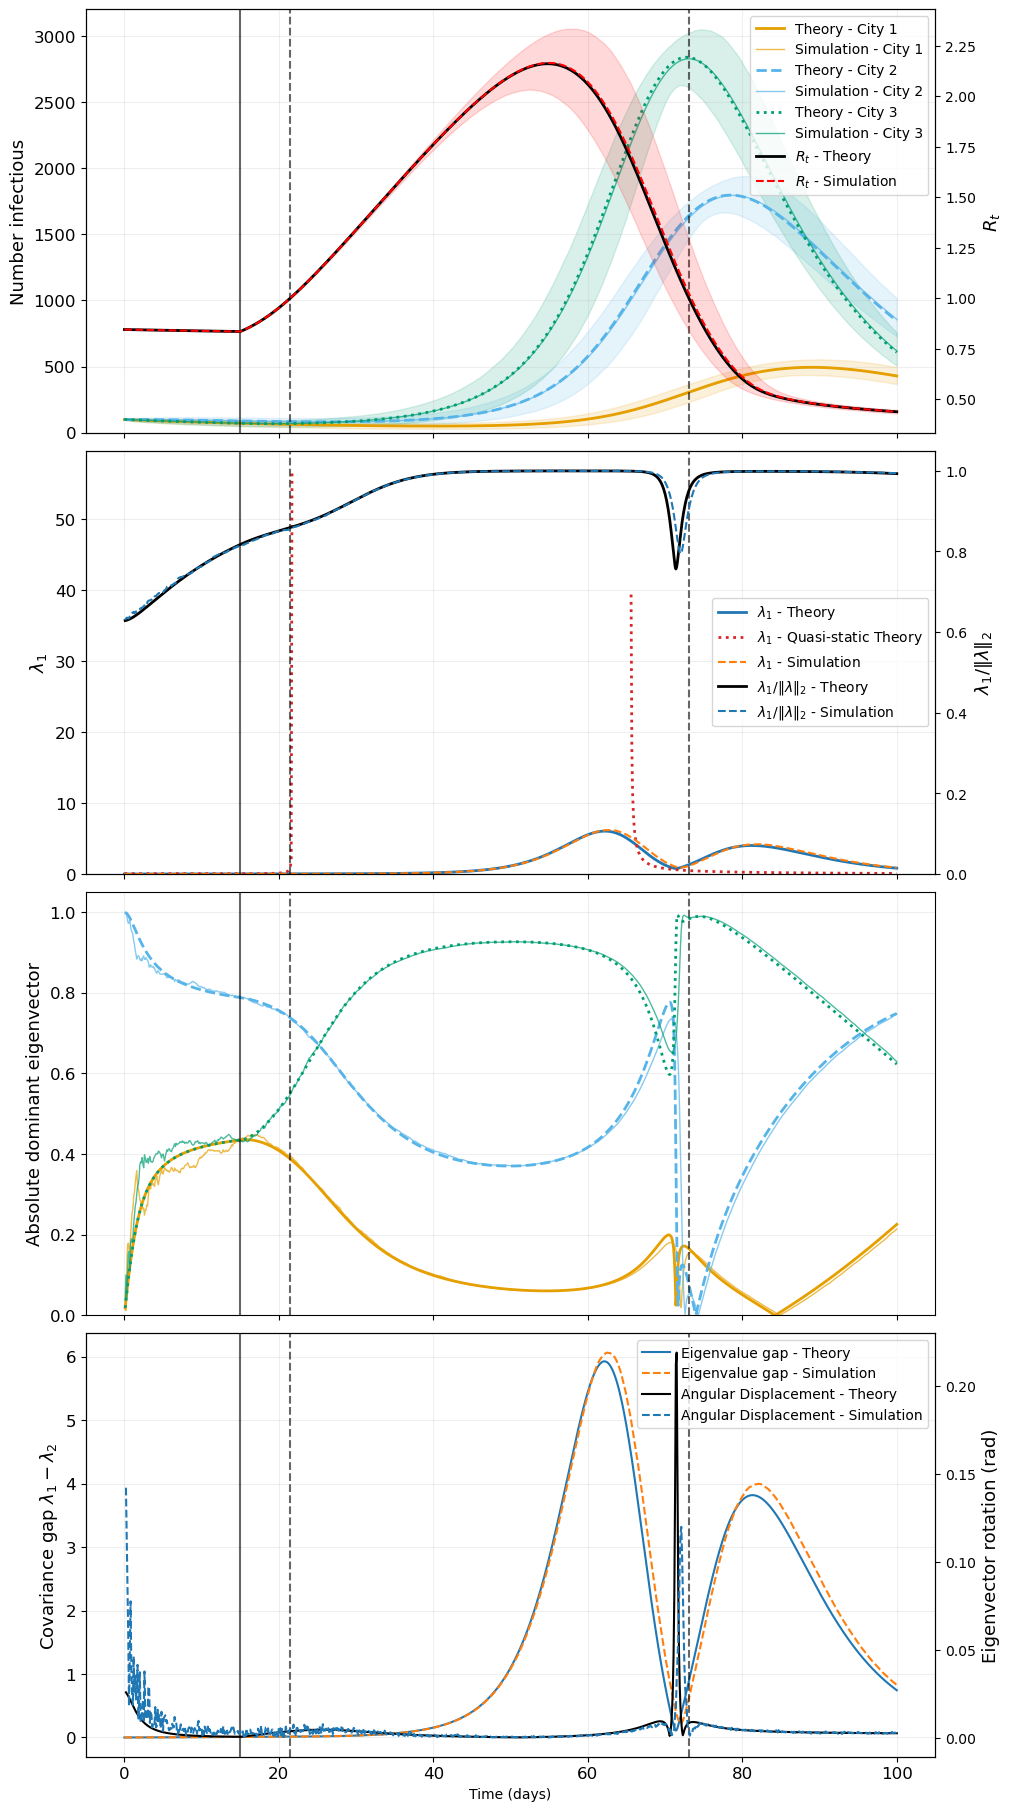

In [15]:
N_cities = 3
T_max = 100
N_population = 10000

Ii = np.array([100,100,100])
Si = N_population - Ii

def betat(t):
    b_w_l = 0.05
    b_b_l = 0.025
    beta_matrix_low = np.array([[b_w_l, b_b_l, 0],
                                [b_b_l, b_w_l, b_b_l],
                                [0,     b_b_l, b_w_l]])
    if t < 15:
        return beta_matrix_low
    else:
        temp = np.array([[0,0,0],
                         [0,0,0.25],
                         [0,0,1]])
        return beta_matrix_low + 0.005*(t-15)*temp

gamma = 0.1
mu = 1/(80*365)
b_w_l = 0.05
b_b_l = 0.025
beta_matrix_low = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,b_b_l],[0,b_b_l,b_w_l]])
print(np.max(np.linalg.eigvals(beta_matrix_low))/(gamma+mu))
beta_matrix_var = np.array([[b_w_l,b_b_l,0],[b_b_l,b_w_l,0.1],[0,b_b_l,0.1]])
print(np.max(np.linalg.eigvals(beta_matrix_var))/(gamma+mu))

results_nv = analyze_epidemic_data('newvar', betat, ts, gamma, mu, N_population, Si, Ii, 0.008)
plot_epidemic_results_single(results_nv, ts, npi_time=15, save_path='Rev_Figures_Small/new_var_theory_small.pdf')

## (Re-)Emergence

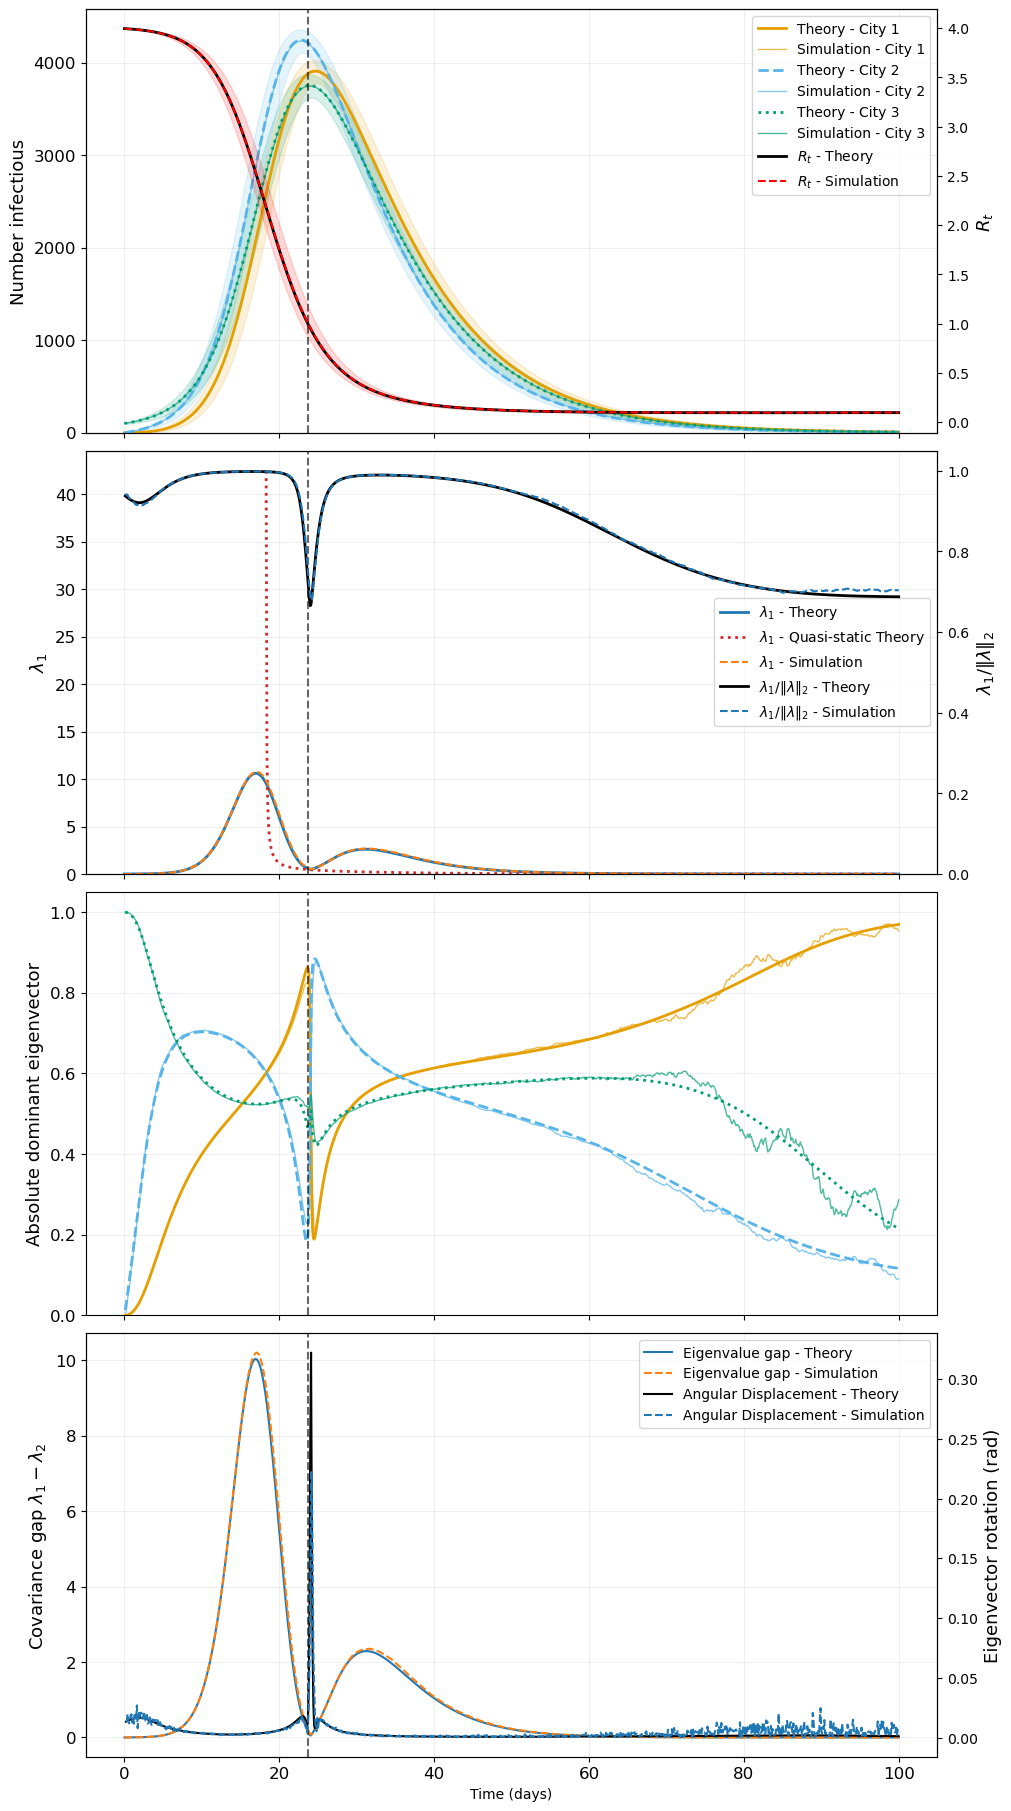

In [16]:
N_cities = 3
T_max = 100
b_w = 0.231
b_b = 0.12
beta_matrix = np.array([[b_w,b_b,0],[b_b,b_w,b_b],[0,b_b,b_w]])
gamma = 0.1
mu = 1/(80*365)
N_population = 10000

Ii = np.array([0,0,100])
Si = N_population - Ii

betat = lambda t: beta_matrix
results_seed = analyze_epidemic_data('seed', betat, ts, gamma, mu, N_population, Si, Ii, 0.005)
plot_epidemic_results_single(results_seed, ts, save_path='Rev_Figures_Small/seed_theory_small.pdf')